In [1]:
import hashlib
import json
import os
import re
import sys
from pathlib import Path

os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

ENTRY_DIR = Path.cwd()
if not (ENTRY_DIR / "config_highway_wocar.json").exists():
    ENTRY_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path("entries/02_wocar_dqn").resolve()
os.chdir(ENTRY_DIR)

for sub in [str(ENTRY_DIR), str(ENTRY_DIR / "common"), str(ENTRY_DIR / "auto_LiRPA"), str(ENTRY_DIR / "upstream")]:
    if sub not in sys.path:
        sys.path.append(sub)
if sys.path[0] != str(ENTRY_DIR):
    sys.path.insert(0, str(ENTRY_DIR))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

torch.set_num_threads(1)

from highway_adapter import LegacyHighwayEnv
from models import model_setup
from train import get_logits_lower_bound

# Restore Jupyter inline backend after utils.py sets matplotlib.use('Agg')
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass

DEVICE = torch.device("cpu")
with open(ENTRY_DIR / "config_highway_wocar.json") as f:
    BASE_CONFIG = json.load(f)

ENV_ID = BASE_CONFIG["env_id"]
ENV_CONFIG = BASE_CONFIG["env_config"]
TRAIN_EPS = float(BASE_CONFIG["training_config"]["epsilon"])  # 0.0025
ACTION_NAMES = {0: "LANE_LEFT", 1: "IDLE", 2: "LANE_RIGHT", 3: "FASTER", 4: "SLOWER"}

MODELS = {
    "Vanilla DQN": {
        "checkpoint": "artifacts/3rd_run/highway-v0_vanilla/best_frame_4000000.pth",
        "train_log": "artifacts/3rd_run/highway-v0_vanilla/train.log",
        "color": "#1f77b4",
        "linestyle": "-",
    },
    "SA-DQN": {
        "checkpoint": "artifacts/3rd_run/highway-v0_sadqn/best_frame_2450000.pth",
        "train_log": "artifacts/3rd_run/highway-v0_sadqn/train.log",
        "color": "#ff7f0e",
        "linestyle": "-",
    },
    "WocaR-DQN (Baseline)": {
        "checkpoint": "artifacts/3rd_run/highway-v0_wocar/best_frame_3850000.pth",
        "train_log": "artifacts/3rd_run/highway-v0_wocar/train.log",
        "color": "#2ca02c",
        "linestyle": "-",
     },
    "Vanilla DQN 2": {
        "checkpoint": "artifacts/vanilla_test/highway-v0_vanilla/best_frame_2450000.pth",
        "train_log": "artifacts/vanilla_test/highway-v0_vanilla/train.log",
        "color": "#d62728",
        "linestyle": "-",
    },
    # Previous runs (uncomment to include in plots):
    # "Run 1 (casstef 2.45M)": {
    #     "checkpoint": "artifacts/1st_run/casstef_4m.pth",
    #     "train_log": "artifacts/1st_run/train.log",
    #     "color": "#7f7f7f",
    #     "linestyle": "--",
    # },
    # "Run 2 (4.0M)": {
    #     "checkpoint": "artifacts/2nd_run/frame_4000000.pth",
    #     "train_log": "artifacts/2nd_run/train.log",
    #     "color": "#9467bd",
    #     "linestyle": ":",
    # },
}

# Evaluation settings
N_EPISODES = 300                     # Deterministic episode seeds 0 .. N_EPISODES-1 (bumped from 100)
EPSILONS = [0.0, 0.0005, 0.001, 0.0025, 0.005, 0.01, 0.02, 0.05]
ATTACK_METHODS = ["random_linf", "pgd", "minbest", "worst_q"]
PGD_STEPS = 10
INCLUDE_IN_PROGRESS_RUNS = False     # Set True to evaluate partial 3rd_run checkpoints before 4M finishes
FORCE_RECOMPUTE = False              # Set True to ignore cached evaluation JSONs

CACHE_DIR = ENTRY_DIR / "artifacts" / "eval_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)


def resolve_checkpoint(spec_path, require_complete=not INCLUDE_IN_PROGRESS_RUNS):
    p = ENTRY_DIR / spec_path
    if p.is_file():
        return p
    if not p.is_dir():
        return None
    if require_complete and not (p / "frame_4000000.pth").exists():
        # Also allow if a post-cleanup README.md exists
        if not (p / "README.md").exists():
            return None
    best_files = sorted(
        p.glob("best_frame_*.pth"),
        key=lambda f: int(re.findall(r"(\d+)", f.stem)[-1]),
    )
    if best_files:
        return best_files[-1]
    frame_files = sorted(
        [f for f in p.glob("frame_*.pth") if f.suffix == ".pth"],
        key=lambda f: int(re.findall(r"(\d+)", f.stem)[-1]),
    )
    return frame_files[-1] if frame_files else None


ACTIVE_MODELS = {}
status_rows = []
for name, meta in MODELS.items():
    ckpt = resolve_checkpoint(meta["checkpoint"])
    log_p = ENTRY_DIR / meta["train_log"] if meta.get("train_log") else None
    if ckpt is not None:
        ACTIVE_MODELS[name] = {**meta, "resolved_ckpt": ckpt}
    status_rows.append({
        "Model": name,
        "Status": "READY" if ckpt is not None else "TRAINING / PENDING",
        "Resolved Checkpoint": str(ckpt.relative_to(ENTRY_DIR)) if ckpt else "-",
        "Train Log": str(log_p.relative_to(ENTRY_DIR)) if (log_p and log_p.exists()) else "-",
    })

pd.DataFrame(status_rows)

objc[27294]: Class SDLApplication is implemented in both /Users/frederikbach/PycharmProjects/models/.venv/lib/python3.14/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x120300890) and /opt/homebrew/Cellar/sdl2/2.32.10/lib/libSDL2-2.0.0.dylib (0x121cd7c88). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[27294]: Class SDLAppDelegate is implemented in both /Users/frederikbach/PycharmProjects/models/.venv/lib/python3.14/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x1203008e0) and /opt/homebrew/Cellar/sdl2/2.32.10/lib/libSDL2-2.0.0.dylib (0x121cd7cd8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[27294]: Class SDLTranslatorResponder is implemented in both /Users/frederikbach/PycharmProjects/models/.venv/lib/python3.14/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x120300958) and /opt/homebrew/Cellar/sdl2/2.32.10/lib/libSDL2-2.0.0.dylib (0x

,Model,Status,Resolved Checkpoint,Train Log
0,Vanilla DQN,READY,artifacts/3rd_run/highway-v0_vanilla/best_fram...,artifacts/3rd_run/highway-v0_vanilla/train.log
1,SA-DQN,READY,artifacts/3rd_run/highway-v0_sadqn/best_frame_...,artifacts/3rd_run/highway-v0_sadqn/train.log
2,WocaR-DQN (Baseline),READY,artifacts/3rd_run/highway-v0_wocar/best_frame_...,artifacts/3rd_run/highway-v0_wocar/train.log
3,Vanilla DQN 2,READY,artifacts/vanilla_test/highway-v0_vanilla/best...,artifacts/vanilla_test/highway-v0_vanilla/trai...


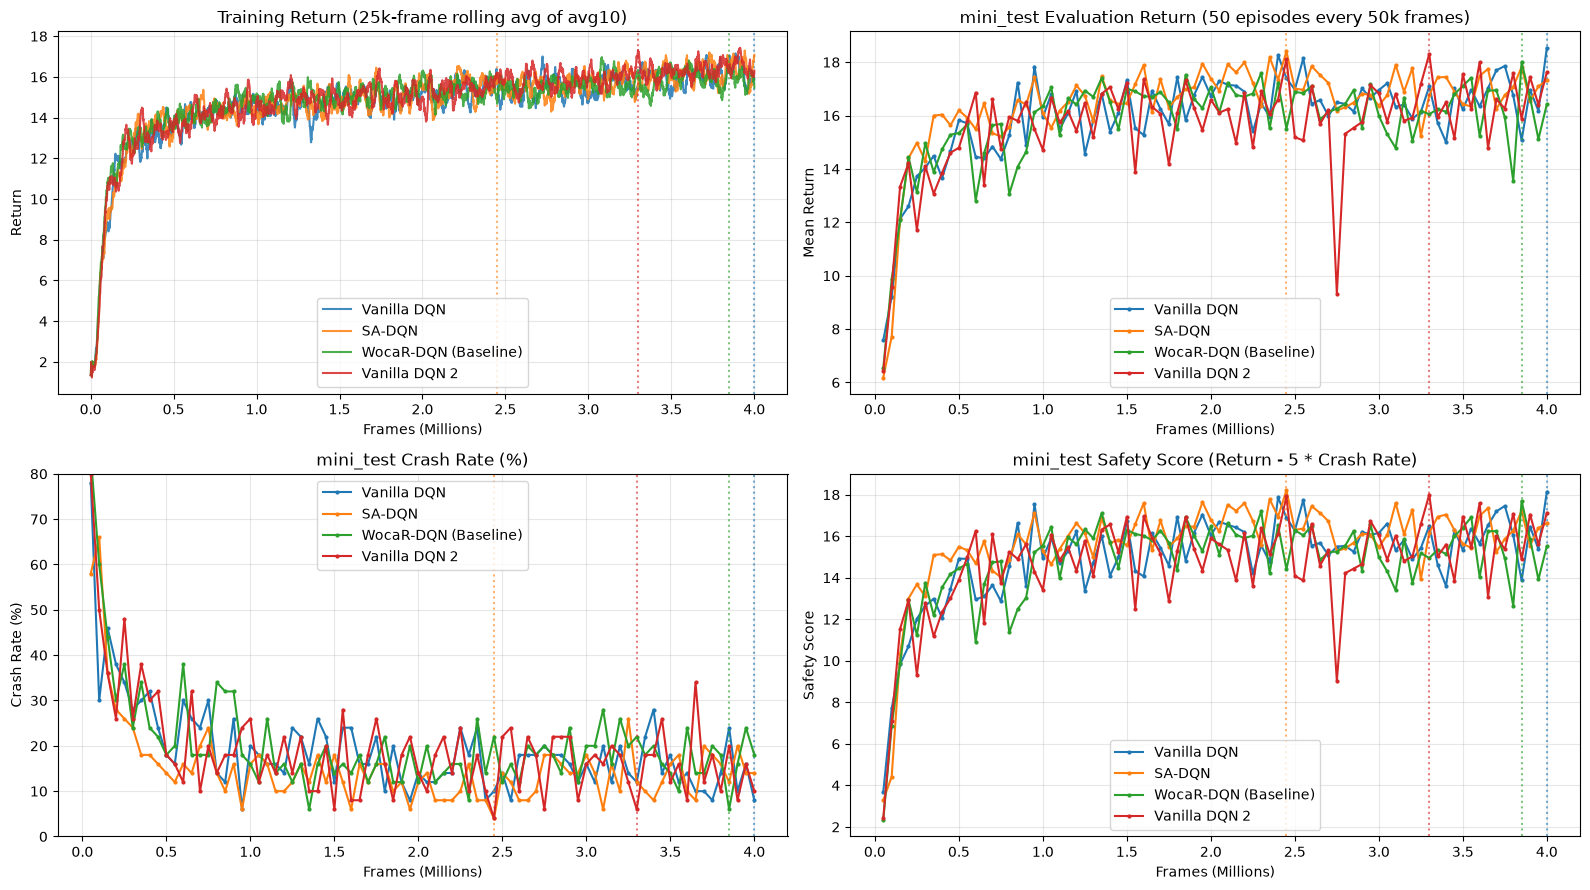

Output()

ToggleButtons(description='Show', options=('Vanilla DQN', 'SA-DQN', 'WocaR-DQN (Baseline)', 'Vanilla DQN 2'), …

,Model,Frames Logged,Best Safety Frame,Best Safety Score,Return @ Best Safety,Crash Rate @ Best Safety,Lowest Crash Rate
0,Vanilla DQN,"4,000,000","4,000,000",18.14,18.54,8.0%,"6.0% (@ 950,000)"
1,SA-DQN,"4,000,000","2,450,000",18.21,18.41,4.0%,"4.0% (@ 2,450,000)"
2,WocaR-DQN (Baseline),"4,000,000","3,850,000",17.70,18.00,6.0%,"6.0% (@ 3,850,000)"
3,Vanilla DQN 2,"4,000,000","3,300,000",18.00,18.30,6.0%,"4.0% (@ 2,450,000)"


In [2]:
FRAME_RE = re.compile(r"^frame\s+(\d+)/(\d+)")
PERF_RE = re.compile(
    r"last total loss:\s*([\d.eE+-]+|nan),\s*avg total loss:\s*([\d.eE+-]+|nan).*"
    r"latest episode reward:\s*([\d.eE+-]+|nan),\s*avg 10 episode reward:\s*([\d.eE+-]+|nan)"
)
TEST_RE = re.compile(
    r"this test avg reward:\s*([\d.eE+-]+),\s*crash rate:\s*([\d.]+),\s*safety score:\s*([\d.eE+-]+)"
)



from tensorboard.backend.event_processing.event_accumulator import EventAccumulator


def parse_tensorboard_log(tb_dir):
    """Fallback parser: read training curves from TensorBoard event files (tensorboard/)."""
    ea = EventAccumulator(str(tb_dir), size_guidance={"limit": 100000})
    ea.Reload()
    scalars = ea.Tags()["scalars"]
    test_ret, test_crash, test_safety = {}, {}, {}
    train_map = {}
    for tag in sorted(scalars):
        for e in ea.Scalars(tag):
            f = int(e.step)
            if tag == "test/return":
                test_ret[f] = float(e.value)
            elif tag == "test/crash_rate":
                test_crash[f] = float(e.value)
            elif tag == "test/safety_score":
                test_safety[f] = float(e.value)
            elif tag == "train/avg_return_10":
                train_map[f] = {"frame": f, "avg_loss": float("nan"), "avg10_return": float(e.value)}
    frames = sorted(set(test_ret) | set(test_crash) | set(test_safety))
    test_rows = [
        {
            "frame": f,
            "test_return": float(test_ret.get(f, float("nan"))),
            "crash_rate": float(test_crash.get(f, float("nan"))),
            "safety_score": float(test_safety.get(f, float("nan"))),
        }
        for f in frames
    ]
    df_tr = pd.DataFrame(sorted(train_map.values(), key=lambda r: r["frame"]), columns=["frame", "avg_loss", "avg10_return"]) if train_map else pd.DataFrame(columns=["frame", "avg_loss", "avg10_return"])
    df_te = pd.DataFrame(test_rows) if test_rows else pd.DataFrame(columns=["frame", "test_return", "crash_rate", "safety_score"])
    return df_tr, df_te



def parse_train_log(log_path):
    train_rows, test_rows = [], []
    cur_frame = 0
    with open(log_path, "r", encoding="utf-8", errors="replace") as f:
        for line in f:
            if line.startswith("frame "):
                m = FRAME_RE.match(line)
                if m:
                    cur_frame = int(m.group(1))
            elif line.startswith("total time:"):
                m = PERF_RE.search(line)
                if m and cur_frame % 1000 == 0:
                    train_rows.append({
                        "frame": cur_frame,
                        "avg_loss": float(m.group(2)),
                        "avg10_return": float(m.group(4)),
                    })
            elif line.startswith("this test avg reward:"):
                m = TEST_RE.search(line)
                if m:
                    test_rows.append({
                        "frame": cur_frame,
                        "test_return": float(m.group(1)),
                        "crash_rate": float(m.group(2)),
                        "safety_score": float(m.group(3)),
                    })
    return pd.DataFrame(train_rows), pd.DataFrame(test_rows)


fig, axes = plt.subplots(2, 2, figsize=(16, 9))
toggle_axes = [axes[0, 0], axes[0, 1], axes[1, 0], axes[1, 1]]
toggle_fig = fig
peak_summary = []

for name, meta in MODELS.items():
    log_rel = meta.get("train_log")
    tb_dir = (ENTRY_DIR / log_rel).parent / "tensorboard" if log_rel else None
    df_tr, df_te = None, None
    if log_rel and (ENTRY_DIR / log_rel).is_file():
        df_tr, df_te = parse_train_log(ENTRY_DIR / log_rel)
    elif tb_dir is not None and tb_dir.is_dir():
        df_tr, df_te = parse_tensorboard_log(tb_dir)
        print(f"[TB] No train.log found - using TensorBoard events for {name}")
    if df_tr is None and df_te is None:
        continue
    color = meta.get("color", None)
    ls = meta.get("linestyle", "-")

    if not df_tr.empty:
        axes[0, 0].plot(
            df_tr["frame"] / 1e6,
            df_tr["avg10_return"].rolling(25, min_periods=1).mean(),
            label=name,
            color=color,
            linestyle=ls,
            alpha=0.85,
        )
    if not df_te.empty:
        axes[0, 1].plot(df_te["frame"] / 1e6, df_te["test_return"], label=name, color=color, linestyle=ls, marker=".", markersize=4)
        axes[1, 0].plot(df_te["frame"] / 1e6, df_te["crash_rate"] * 100, label=name, color=color, linestyle=ls, marker=".", markersize=4)
        axes[1, 1].plot(df_te["frame"] / 1e6, df_te["safety_score"], label=name, color=color, linestyle=ls, marker=".", markersize=4)

        best_idx = df_te["safety_score"].idxmax()
        best_row = df_te.loc[best_idx]
        min_crash_row = df_te.sort_values(["crash_rate", "test_return"], ascending=[True, False]).iloc[0]
        peak_summary.append({
            "Model": name,
            "Frames Logged": f"{int(df_tr['frame'].max()):,}" if not df_tr.empty else "-",
            "Best Safety Frame": f"{int(best_row['frame']):,}",
            "Best Safety Score": round(best_row["safety_score"], 2),
            "Return @ Best Safety": round(best_row["test_return"], 2),
            "Crash Rate @ Best Safety": f"{best_row['crash_rate']*100:.1f}%",
            "Lowest Crash Rate": f"{min_crash_row['crash_rate']*100:.1f}% (@ {int(min_crash_row['frame']):,})",
        })

        for ax in (axes[0, 0], axes[0, 1], axes[1, 0], axes[1, 1]):
            ax.axvline(float(best_row["frame"]) / 1e6, color=color, linestyle=":", alpha=0.6, label="_nolegend_")

axes[0, 0].set_title("Training Return (25k-frame rolling avg of avg10)")
axes[0, 0].set_xlabel("Frames (Millions)"); axes[0, 0].set_ylabel("Return"); axes[0, 0].grid(alpha=0.3); axes[0, 0].legend()

axes[0, 1].set_title("mini_test Evaluation Return (50 episodes every 50k frames)")
axes[0, 1].set_xlabel("Frames (Millions)"); axes[0, 1].set_ylabel("Mean Return"); axes[0, 1].grid(alpha=0.3); axes[0, 1].legend()

axes[1, 0].set_title("mini_test Crash Rate (%)")
axes[1, 0].set_xlabel("Frames (Millions)"); axes[1, 0].set_ylabel("Crash Rate (%)"); axes[1, 0].set_ylim(0, 80); axes[1, 0].grid(alpha=0.3); axes[1, 0].legend()

axes[1, 1].set_title("mini_test Safety Score (Return - 5 * Crash Rate)")
axes[1, 1].set_xlabel("Frames (Millions)"); axes[1, 1].set_ylabel("Safety Score"); axes[1, 1].grid(alpha=0.3); axes[1, 1].legend()

plt.tight_layout()
plt.show()

# Interactive line toggles for the training/eval curves.
from ipywidgets import ToggleButtons, Output
from IPython.display import display

model_names = list(MODELS.keys())
toggles = ToggleButtons(
    options=model_names,
    value=model_names[0],
    description="Show",
    disabled=False,
)

out = Output()

def _update_visibility(change=None):
    selected = {toggles.value}
    for ax in toggle_axes:
        for line in ax.lines:
            if line.get_label() in selected:
                line.set_visible(True)
            elif line.get_label() in MODELS:
                line.set_visible(False)
    toggle_fig.canvas.draw_idle()
    toggle_fig.canvas.draw()

toggles.observe(_update_visibility, names="value")
_update_visibility()
display(out, toggles)

pd.DataFrame(peak_summary)

In [3]:
def load_q_models(ckpt_path, env):
    state_dict = torch.load(ckpt_path, map_location=DEVICE)
    # Fast inference model (plain nn.Sequential for clean/PGD rollouts)
    fast_model = model_setup(ENV_ID, env, robust_model=False, logger=None, use_cuda=False, dueling=True, model_width=1)
    fast_model.features.load_state_dict(state_dict)
    fast_model.eval()

    # BoundedModule model for auto_LiRPA certification
    cert_model = model_setup(ENV_ID, env, robust_model=True, logger=None, use_cuda=False, dueling=True, model_width=1)
    cert_model.features.load_state_dict(state_dict)
    cert_model.eval()
    return fast_model, cert_model


def perturb_observation(model, state_tensor, method, eps, rng, niters=PGD_STEPS):
    if eps <= 0.0 or method == "clean":
        return state_tensor

    if method == "random_linf":
        noise = torch.from_numpy(rng.uniform(-eps, eps, size=state_tensor.shape).astype(np.float32))
        return state_tensor + noise

    with torch.no_grad():
        clean_q = model(state_tensor)
        best_action = clean_q.argmax(dim=1)
        worst_action = clean_q.argmin(dim=1)

    step_size = max(eps / float(niters), 1e-6)
    init_noise = torch.from_numpy(rng.uniform(-eps, eps, size=state_tensor.shape).astype(np.float32))
    x_adv = (state_tensor + init_noise).clamp(state_tensor - eps, state_tensor + eps).detach()

    for _ in range(niters):
        x_adv.requires_grad_(True)
        q_adv = model(x_adv)
        if method == "pgd":
            loss = nn.CrossEntropyLoss()(q_adv, best_action)
        elif method == "minbest":
            mask = torch.zeros_like(q_adv).scatter_(1, best_action.unsqueeze(1), 1e10)
            runner_up = (q_adv - mask).max(dim=1)[0]
            chosen_q = q_adv.gather(1, best_action.unsqueeze(1)).squeeze(1)
            loss = (runner_up - chosen_q).sum()
        elif method == "worst_q":
            worst_q = q_adv.gather(1, worst_action.unsqueeze(1)).squeeze(1)
            chosen_q = q_adv.gather(1, best_action.unsqueeze(1)).squeeze(1)
            loss = (worst_q - chosen_q).sum()
        else:
            raise ValueError(f"Unknown attack method: {method}")

        model.zero_grad()
        loss.backward()
        grad_sign = x_adv.grad.detach().sign()
        x_adv = (x_adv.detach() + step_size * grad_sign).clamp(state_tensor - eps, state_tensor + eps)

    return x_adv.detach()


def is_state_certified(cert_model, state_tensor, clean_action, eps):
    if eps <= 0.0:
        return True
    num_actions = cert_model.num_actions
    max_logit = torch.tensor([int(clean_action)], dtype=torch.long)
    eye = torch.eye(num_actions, dtype=state_tensor.dtype)
    c = eye[max_logit].unsqueeze(1) - eye.unsqueeze(0)
    I = ~(max_logit.unsqueeze(1) == torch.arange(num_actions).unsqueeze(0))
    c = c[I].view(1, num_actions - 1, num_actions)
    state_ub = state_tensor + eps
    state_lb = state_tensor - eps
    with torch.no_grad():
        lb = get_logits_lower_bound(cert_model, state_tensor, state_ub, state_lb, eps, c, beta=0.0)
    return bool((lb[0].min().item()) > 0.0)


def compute_cache_path(model_name, ckpt_path):
    h = hashlib.sha256()
    h.update(ckpt_path.read_bytes())
    cfg_sig = json.dumps({
        "n_episodes": N_EPISODES,
        "epsilons": EPSILONS,
        "methods": ATTACK_METHODS,
        "pgd_steps": PGD_STEPS,
        "env_config": ENV_CONFIG,
        "v": 1,
    }, sort_keys=True).encode()
    h.update(cfg_sig)
    slug = re.sub(r"[^a-zA-Z0-9_]+", "_", model_name).strip("_").lower()
    return CACHE_DIR / f"{slug}_{h.hexdigest()[:12]}.json"


def evaluate_model_suite(model_name, ckpt_path):
    cache_file = compute_cache_path(model_name, ckpt_path)
    if cache_file.exists() and not FORCE_RECOMPUTE:
        print(f"[CACHE HIT] Loading {model_name} from {cache_file.relative_to(ENTRY_DIR)}")
        with open(cache_file, "r") as f:
            return json.load(f)

    print(f"[EVALUATING] {model_name} ({ckpt_path.relative_to(ENTRY_DIR)}) over {N_EPISODES} episodes...")
    env = LegacyHighwayEnv(ENV_ID, ENV_CONFIG)
    fast_model, cert_model = load_q_models(ckpt_path, env)

    # 1) Clean baseline rollout + collect clean states for certification
    clean_returns, clean_lengths, clean_crashes = [], [], []
    action_counts = {a: 0 for a in range(env.action_space.n)}
    clean_states = []
    clean_actions = []
    clean_importances = []

    for ep in range(N_EPISODES):
        env.seed(ep)
        state = env.reset()
        done = False
        ep_ret, steps, crashed = 0.0, 0, False
        while not done:
            s_t = torch.from_numpy(np.ascontiguousarray(state)).unsqueeze(0)
            with torch.no_grad():
                q_vals = fast_model(s_t)[0]
                act = int(q_vals.argmax().item())
                imp = float((q_vals.max() - q_vals.min()).item())
            clean_states.append(s_t)
            clean_actions.append(act)
            clean_importances.append(imp)
            action_counts[act] += 1
            state, reward, done, info = env.step(act)
            ep_ret += float(reward)
            steps += 1
            crashed = crashed or bool(info.get("crashed", False))
        clean_returns.append(ep_ret)
        clean_lengths.append(steps)
        clean_crashes.append(bool(crashed))

    total_clean_steps = max(1, sum(action_counts.values()))
    imp_threshold_75 = float(np.percentile(clean_importances, 75)) if clean_importances else 0.0

    # 2) Certified Action Ratio across EPSILONS on the visited clean states
    cert_ratios = {}
    for eps in EPSILONS:
        if eps == 0.0:
            cert_ratios[str(eps)] = 1.0
        else:
            cert_hits = sum(
                is_state_certified(cert_model, s_t, act, eps)
                for s_t, act in zip(clean_states, clean_actions)
            )
            cert_ratios[str(eps)] = float(cert_hits / len(clean_states))

    # 3) Empirical attack & noise sweeps
    sweep_rows = []
    for method in ATTACK_METHODS:
        for eps in EPSILONS:
            if eps == 0.0:
                sweep_rows.append({
                    "method": method,
                    "epsilon": 0.0,
                    "mean_return": float(np.mean(clean_returns)),
                    "std_return": float(np.std(clean_returns)),
                    "mean_length": float(np.mean(clean_lengths)),
                    "crash_rate": float(np.mean(clean_crashes)),
                    "safety_score": float(np.mean(clean_returns) - 5.0 * np.mean(clean_crashes)),
                    "flip_rate": 0.0,
                    "critical_flip_rate": 0.0,
                    "noncritical_flip_rate": 0.0,
                })
                continue

            rng = np.random.RandomState(1234)
            rets, lens, crashes = [], [], []
            flips, total_steps = 0, 0
            crit_flips, crit_steps = 0, 0
            noncrit_flips, noncrit_steps = 0, 0

            for ep in range(N_EPISODES):
                env.seed(ep)
                state = env.reset()
                done = False
                ep_ret, steps, crashed = 0.0, 0, False
                while not done:
                    s_t = torch.from_numpy(np.ascontiguousarray(state)).unsqueeze(0)
                    with torch.no_grad():
                        q_clean = fast_model(s_t)[0]
                        act_clean = int(q_clean.argmax().item())
                        imp = float((q_clean.max() - q_clean.min()).item())

                    s_adv = perturb_observation(fast_model, s_t, method, eps, rng)
                    with torch.no_grad():
                        act_adv = int(fast_model(s_adv)[0].argmax().item())

                    flipped = int(act_adv != act_clean)
                    flips += flipped
                    total_steps += 1
                    if imp >= imp_threshold_75:
                        crit_flips += flipped
                        crit_steps += 1
                    else:
                        noncrit_flips += flipped
                        noncrit_steps += 1

                    state, reward, done, info = env.step(act_adv)
                    ep_ret += float(reward)
                    steps += 1
                    crashed = crashed or bool(info.get("crashed", False))
                rets.append(ep_ret)
                lens.append(steps)
                crashes.append(bool(crashed))

            sweep_rows.append({
                "method": method,
                "epsilon": float(eps),
                "mean_return": float(np.mean(rets)),
                "std_return": float(np.std(rets)),
                "mean_length": float(np.mean(lens)),
                "crash_rate": float(np.mean(crashes)),
                "safety_score": float(np.mean(rets) - 5.0 * np.mean(crashes)),
                "flip_rate": float(flips / max(1, total_steps)),
                "critical_flip_rate": float(crit_flips / max(1, crit_steps)),
                "noncritical_flip_rate": float(noncrit_flips / max(1, noncrit_steps)),
            })
            print(
                f"  {method:11s} eps={eps:.4f} | return={np.mean(rets):6.2f} "
                f"crash={np.mean(crashes)*100:4.1f}% flip={flips/max(1,total_steps)*100:4.1f}%"
            )

    env.close()
    payload = {
        "model_name": model_name,
        "checkpoint": str(ckpt_path.relative_to(ENTRY_DIR)),
        "clean": {
            "mean_return": float(np.mean(clean_returns)),
            "std_return": float(np.std(clean_returns)),
            "mean_length": float(np.mean(clean_lengths)),
            "std_length": float(np.std(clean_lengths)),
            "crash_rate": float(np.mean(clean_crashes)),
            "safety_score": float(np.mean(clean_returns) - 5.0 * np.mean(clean_crashes)),
            "mean_importance_w": float(np.mean(clean_importances)),
            "action_fractions": {ACTION_NAMES[k]: v / total_clean_steps for k, v in action_counts.items()},
            "episode_returns": clean_returns,
        },
        "certified_ratios": cert_ratios,
        "sweeps": sweep_rows,
    }
    with open(cache_file, "w") as f:
        json.dump(payload, f, indent=2)
    return payload


ALL_RESULTS = {}
for name, meta in ACTIVE_MODELS.items():
    ALL_RESULTS[name] = evaluate_model_suite(name, meta["resolved_ckpt"])

[CACHE HIT] Loading Vanilla DQN from artifacts/eval_cache/vanilla_dqn_56df8fd723be.json
[CACHE HIT] Loading SA-DQN from artifacts/eval_cache/sa_dqn_149ac152b5c3.json
[CACHE HIT] Loading WocaR-DQN (Baseline) from artifacts/eval_cache/wocar_dqn_baseline_8d7b0d9c24e1.json
[CACHE HIT] Loading Vanilla DQN 2 from artifacts/eval_cache/vanilla_dqn_2_67c08182301c.json


,Model,Mean Return,Crash Rate,Safety Score,Mean Length (max 40),Cert Ratio @ eps=0.0025,LANE_LEFT,IDLE,LANE_RIGHT,FASTER,SLOWER
0,Vanilla DQN,16.30 ± 6.28,19.7%,15.32,34.93,0.5%,7.3%,26.9%,60.5%,4.4%,0.9%
1,SA-DQN,16.04 ± 6.63,19.0%,15.09,34.55,1.0%,8.4%,4.4%,19.0%,67.0%,1.1%
2,WocaR-DQN (Baseline),16.42 ± 5.96,15.0%,15.67,35.70,1.1%,17.2%,23.0%,24.9%,33.1%,1.8%
3,Vanilla DQN 2,16.56 ± 5.73,14.7%,15.82,36.06,0.2%,9.2%,67.1%,12.5%,10.1%,1.1%


/var/folders/mj/s4dq_ptj6xxgpjw7v72t3n0h0000gn/T/ipykernel_27294/2363045641.py:41: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(


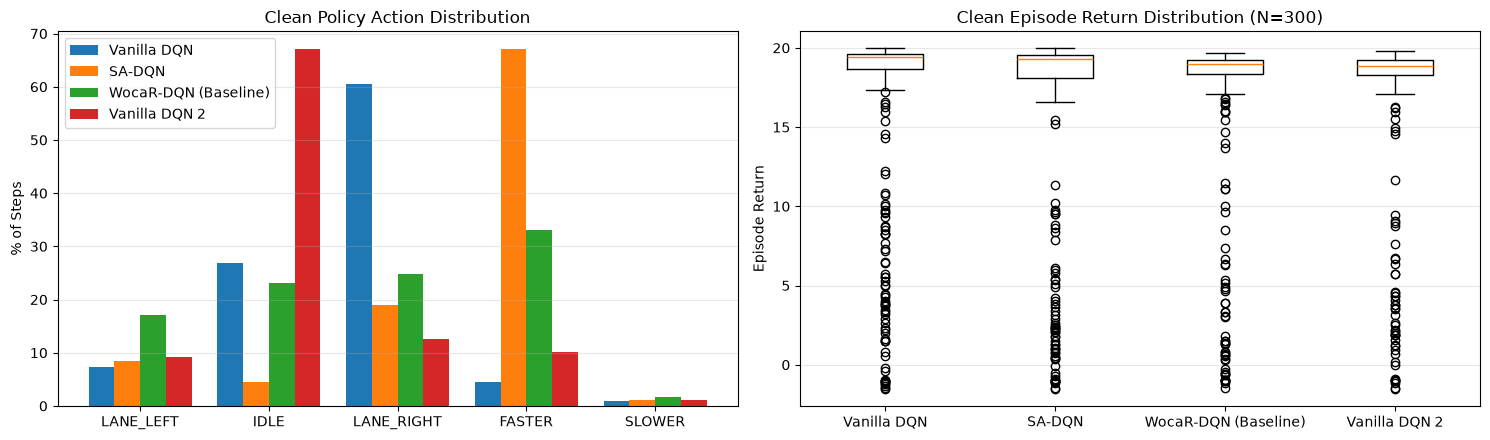

In [4]:
clean_table = []
for name, res in ALL_RESULTS.items():
    c = res["clean"]
    row = {
        "Model": name,
        "Mean Return": f"{c['mean_return']:.2f} ± {c['std_return']:.2f}",
        "Crash Rate": f"{c['crash_rate']*100:.1f}%",
        "Safety Score": round(c["safety_score"], 2),
        "Mean Length (max 40)": f"{c['mean_length']:.2f}",
        "Cert Ratio @ eps=0.0025": f"{res['certified_ratios'].get(str(TRAIN_EPS), 0.0)*100:.1f}%",
    }
    for act_label, frac in c["action_fractions"].items():
        row[act_label] = f"{frac*100:.1f}%"
    clean_table.append(row)

df_clean_summary = pd.DataFrame(clean_table)
display(df_clean_summary)

if ALL_RESULTS:
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
    model_names = list(ALL_RESULTS.keys())
    x = np.arange(len(ACTION_NAMES))
    width = 0.8 / max(1, len(model_names))

    for idx, name in enumerate(model_names):
        fracs = [ALL_RESULTS[name]["clean"]["action_fractions"][ACTION_NAMES[a]] * 100 for a in range(len(ACTION_NAMES))]
        axes[0].bar(
            x + (idx - (len(model_names) - 1) / 2) * width,
            fracs,
            width=width,
            label=name,
            color=ACTIVE_MODELS[name].get("color"),
        )
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(list(ACTION_NAMES.values()))
    axes[0].set_ylabel("% of Steps")
    axes[0].set_title("Clean Policy Action Distribution")
    axes[0].grid(axis="y", alpha=0.3)
    axes[0].legend()

    axes[1].boxplot(
        [ALL_RESULTS[name]["clean"]["episode_returns"] for name in model_names],
        tick_labels=model_names,
        vert=True,
    )
    axes[1].set_ylabel("Episode Return")
    axes[1].set_title(f"Clean Episode Return Distribution (N={N_EPISODES})")
    axes[1].grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

In [5]:
def build_paper_table(target_eps):
    rows = []
    for name, res in ALL_RESULTS.items():
        c = res["clean"]
        df_s = pd.DataFrame(res["sweeps"])
        row = {
            "Model": name,
            "Natural Return": f"{c['mean_return']:.2f} ± {c['std_return']:.2f}",
            "Natural Crash": f"{c['crash_rate']*100:.1f}%",
        }
        for m_key, m_label in [
            ("random_linf", "Random Noise"),
            ("pgd", "PGD (10-step)"),
            ("minbest", "MinBest"),
            ("worst_q", "Worst-Action (Min-Q)"),
        ]:
            sub = df_s[(df_s["method"] == m_key) & (np.isclose(df_s["epsilon"], target_eps))]
            if not sub.empty:
                r = sub.iloc[0]
                row[f"{m_label} Return"] = f"{r['mean_return']:.2f} ± {r['std_return']:.2f}"
                row[f"{m_label} Crash"] = f"{r['crash_rate']*100:.1f}%"
        rows.append(row)
    return pd.DataFrame(rows)


print(f"=== Table A: Robustness at Training Budget (epsilon = {TRAIN_EPS}) ===")
display(build_paper_table(TRAIN_EPS))

print(f"\n=== Table B: Robustness at 2x Training Budget (epsilon = {TRAIN_EPS * 2:.4f}) ===")
display(build_paper_table(TRAIN_EPS * 2))

=== Table A: Robustness at Training Budget (epsilon = 0.0025) ===


,Model,Natural Return,Natural Crash,Random Noise Return,Random Noise Crash,PGD (10-step) Return,PGD (10-step) Crash,MinBest Return,MinBest Crash,Worst-Action (Min-Q) Return,Worst-Action (Min-Q) Crash
0,Vanilla DQN,16.30 ± 6.28,19.7%,16.03 ± 6.47,22.3%,14.91 ± 6.78,32.7%,15.30 ± 6.54,29.3%,15.10 ± 6.89,29.0%
1,SA-DQN,16.04 ± 6.63,19.0%,15.93 ± 6.62,20.7%,14.05 ± 7.76,31.7%,14.59 ± 7.31,29.0%,14.62 ± 7.42,27.7%
2,WocaR-DQN (Baseline),16.42 ± 5.96,15.0%,16.46 ± 5.85,14.7%,15.59 ± 6.28,21.0%,15.84 ± 6.10,20.3%,15.85 ± 6.21,20.0%
3,Vanilla DQN 2,16.56 ± 5.73,14.7%,16.67 ± 5.65,13.7%,15.63 ± 6.46,20.3%,16.09 ± 6.09,17.3%,15.35 ± 6.65,22.3%



=== Table B: Robustness at 2x Training Budget (epsilon = 0.0050) ===


,Model,Natural Return,Natural Crash,Random Noise Return,Random Noise Crash,PGD (10-step) Return,PGD (10-step) Crash,MinBest Return,MinBest Crash,Worst-Action (Min-Q) Return,Worst-Action (Min-Q) Crash
0,Vanilla DQN,16.30 ± 6.28,19.7%,15.60 ± 6.69,25.3%,13.35 ± 7.38,42.7%,12.99 ± 7.47,44.0%,12.88 ± 7.78,44.3%
1,SA-DQN,16.04 ± 6.63,19.0%,15.66 ± 6.77,22.0%,12.04 ± 8.23,43.7%,12.75 ± 8.00,39.7%,12.68 ± 8.09,41.3%
2,WocaR-DQN (Baseline),16.42 ± 5.96,15.0%,16.28 ± 6.00,16.0%,13.16 ± 7.43,38.7%,13.96 ± 7.03,34.0%,14.07 ± 7.05,33.0%
3,Vanilla DQN 2,16.56 ± 5.73,14.7%,16.44 ± 5.89,15.7%,13.79 ± 7.33,34.0%,14.48 ± 7.04,29.0%,13.86 ± 7.45,33.0%


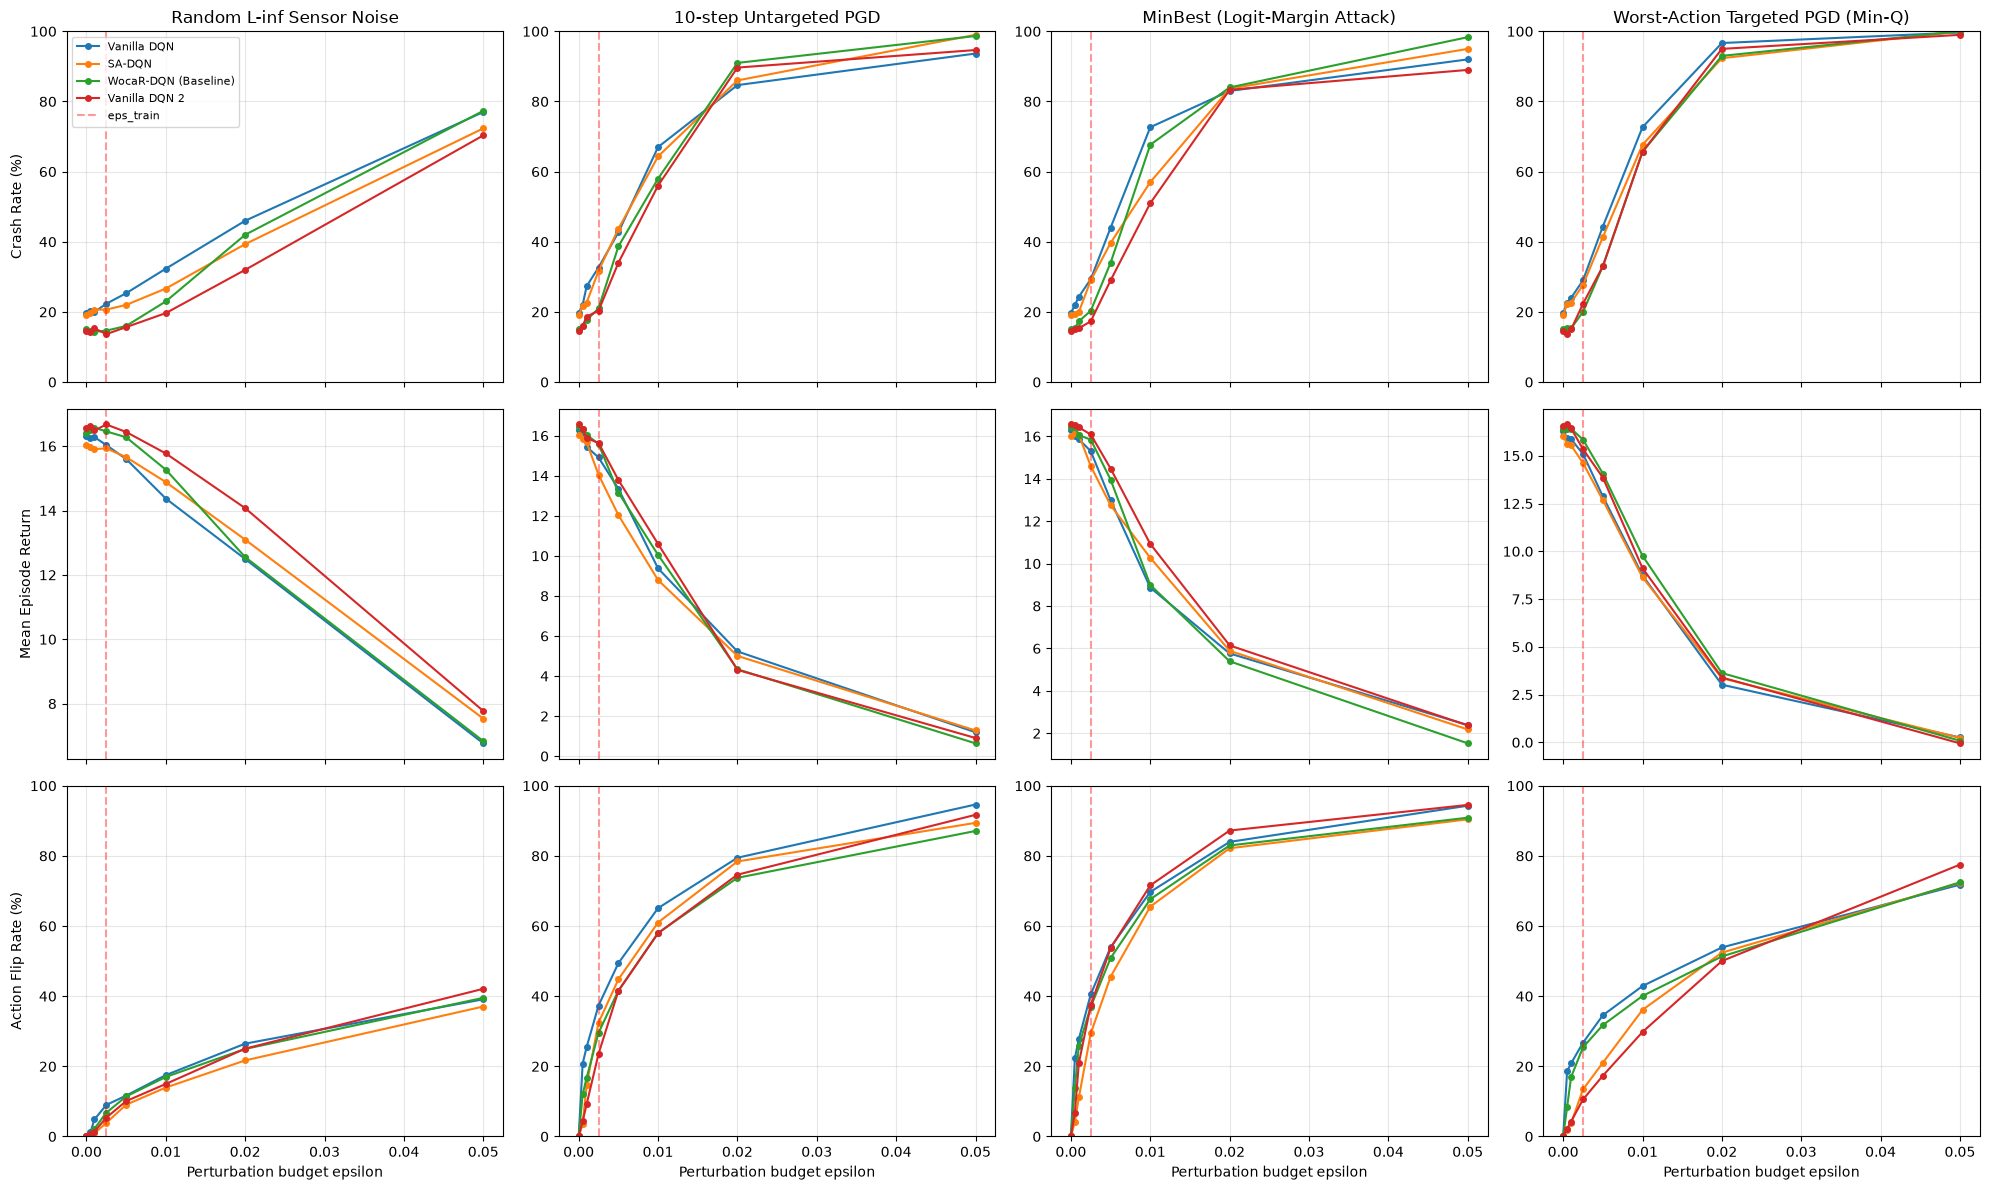

In [6]:
METHOD_TITLES = {
    "random_linf": "Random L-inf Sensor Noise",
    "pgd": "10-step Untargeted PGD",
    "minbest": "MinBest (Logit-Margin Attack)",
    "worst_q": "Worst-Action Targeted PGD (Min-Q)",
}

if ALL_RESULTS:
    fig, axes = plt.subplots(3, 4, figsize=(20, 12), sharex=True)

    for col_idx, method in enumerate(ATTACK_METHODS):
        for name, res in ALL_RESULTS.items():
            df_s = pd.DataFrame(res["sweeps"])
            sub = df_s[df_s["method"] == method].sort_values("epsilon")
            color = ACTIVE_MODELS[name].get("color")
            ls = ACTIVE_MODELS[name].get("linestyle", "-")

            axes[0, col_idx].plot(sub["epsilon"], sub["crash_rate"] * 100, marker="o", markersize=4, label=name, color=color, linestyle=ls)
            axes[1, col_idx].plot(sub["epsilon"], sub["mean_return"], marker="o", markersize=4, label=name, color=color, linestyle=ls)
            axes[2, col_idx].plot(sub["epsilon"], sub["flip_rate"] * 100, marker="o", markersize=4, label=name, color=color, linestyle=ls)

        for row_idx in range(3):
            axes[row_idx, col_idx].axvline(TRAIN_EPS, color="red", linestyle="--", alpha=0.4, label="eps_train" if row_idx == 0 else None)
            axes[row_idx, col_idx].grid(alpha=0.3)

        axes[0, col_idx].set_title(METHOD_TITLES[method])
        axes[0, col_idx].set_ylim(0, 100)
        axes[2, col_idx].set_ylim(0, 100)
        axes[2, col_idx].set_xlabel("Perturbation budget epsilon")

    axes[0, 0].set_ylabel("Crash Rate (%)")
    axes[1, 0].set_ylabel("Mean Episode Return")
    axes[2, 0].set_ylabel("Action Flip Rate (%)")
    axes[0, 0].legend(loc="upper left", fontsize=8)

    plt.tight_layout()
    plt.show()

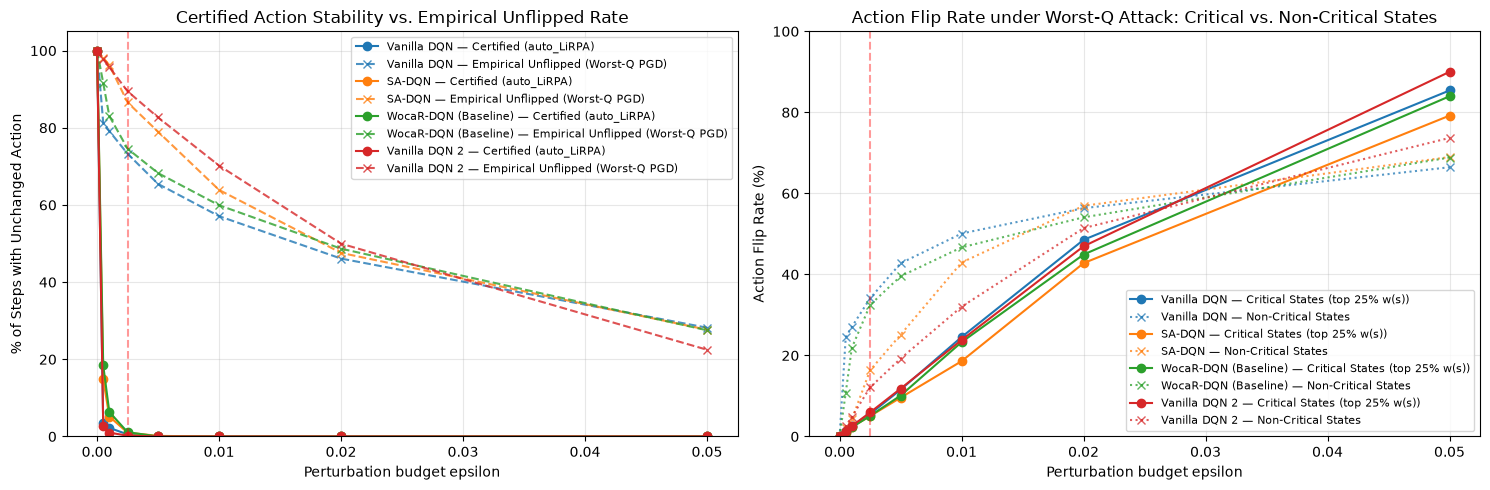

In [7]:
if ALL_RESULTS:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    for name, res in ALL_RESULTS.items():
        color = ACTIVE_MODELS[name].get("color")
        eps_vals = sorted([float(k) for k in res["certified_ratios"].keys()])
        cert_pct = [res["certified_ratios"][str(e)] * 100 for e in eps_vals]

        df_s = pd.DataFrame(res["sweeps"])
        sub_w = df_s[df_s["method"] == "worst_q"].sort_values("epsilon")

        axes[0].plot(eps_vals, cert_pct, marker="o", linestyle="-", color=color, label=f"{name} — Certified (auto_LiRPA)")
        axes[0].plot(sub_w["epsilon"], (1.0 - sub_w["flip_rate"]) * 100, marker="x", linestyle="--", color=color, alpha=0.8, label=f"{name} — Empirical Unflipped (Worst-Q PGD)")

        axes[1].plot(sub_w["epsilon"], sub_w["critical_flip_rate"] * 100, marker="o", linestyle="-", color=color, label=f"{name} — Critical States (top 25% w(s))")
        axes[1].plot(sub_w["epsilon"], sub_w["noncritical_flip_rate"] * 100, marker="x", linestyle=":", color=color, alpha=0.75, label=f"{name} — Non-Critical States")

    axes[0].axvline(TRAIN_EPS, color="red", linestyle="--", alpha=0.4)
    axes[0].set_title("Certified Action Stability vs. Empirical Unflipped Rate")
    axes[0].set_xlabel("Perturbation budget epsilon")
    axes[0].set_ylabel("% of Steps with Unchanged Action")
    axes[0].set_ylim(0, 105)
    axes[0].grid(alpha=0.3)
    axes[0].legend(fontsize=8)

    axes[1].axvline(TRAIN_EPS, color="red", linestyle="--", alpha=0.4)
    axes[1].set_title("Action Flip Rate under Worst-Q Attack: Critical vs. Non-Critical States")
    axes[1].set_xlabel("Perturbation budget epsilon")
    axes[1].set_ylabel("Action Flip Rate (%)")
    axes[1].set_ylim(0, 100)
    axes[1].grid(alpha=0.3)
    axes[1].legend(fontsize=8)

    plt.tight_layout()
    plt.show()